In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# --- Experiment utilities: official 60/20/20 split + MLflow (overwrite) ---
import sys, os
from pathlib import Path

# === Determinism: seed all RNGs for reproducible results (as in week3/tier1_score_generation.ipynb) ===
import random
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Use a seeded generator for DataLoader shuffle
g = torch.Generator()
g.manual_seed(SEED)

print(f"All RNGs seeded with SEED={SEED}")

_exp_root = Path.cwd()
while not (_exp_root / 'pyproject.toml').exists() and _exp_root != _exp_root.parent:
    _exp_root = _exp_root.parent
if str(_exp_root / 'week2' / 'experiments') not in sys.path:
    sys.path.insert(0, str(_exp_root / 'week2' / 'experiments'))
import experiment_utils as eu
import mlflow
# Tracking URI is set to project-root mlflow.db by experiment_utils.start_overwritable_run()
# --- Dataset: original engineered daily dataset for this modality ---
DATA_PATH = str(_exp_root / 'data' / 'dayr4.2.csv')

EXPERIMENT_NAME = 'Week2_Logon_Experiments'
RUN_NAME = 'logon_experiment_1'


All RNGs seeded with SEED=42


In [2]:
# ---------------------------------------------------------------------
# Config
# ---------------------------------------------------------------------
 
TARGET_COL = "insider"
SORT_COLS = ["user", "week", "day"]
 
PERSONALITY_FEATURES = ["O", "C", "E", "A", "N"]
 
LOGON_FEATURES = [
    "n_logon",
    "logon_n-pc0", "logon_n-pc1", "logon_n-pc2", "logon_n-pc3",
    "n_workhourlogon",
    "workhourlogon_n-pc0", "workhourlogon_n-pc1", "workhourlogon_n-pc2", "workhourlogon_n-pc3",
    "n_afterhourlogon",
    "afterhourlogon_n-pc0", "afterhourlogon_n-pc1", "afterhourlogon_n-pc2", "afterhourlogon_n-pc3",
]
 
FEATURE_COLS = PERSONALITY_FEATURES + LOGON_FEATURES
 
RANDOM_STATE = 42
TEST_SIZE = 0.2
DEFAULT_SEQUENCE_LENGTH = 7
STRIDE = 1
 


In [3]:
# ---------------------------------------------------------------------
# 1. Load + sort
# ---------------------------------------------------------------------
 
def load_data(csv_path: str) -> pd.DataFrame:
    """Load the raw daily feature CSV."""
    df = pd.read_csv(csv_path)
    return df
 
 
def sort_data(df: pd.DataFrame) -> pd.DataFrame:
    """Sort records by user, then week, then day so that each user's
    rows form a chronologically ordered timeline (required for later
    sliding-window sequence generation)."""
    missing = [c for c in SORT_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required sort columns: {missing}")
    df_sorted = df.sort_values(by=SORT_COLS).reset_index(drop=True)
    return df_sorted
 


In [4]:
# ---------------------------------------------------------------------
# 2. Feature selection
# ---------------------------------------------------------------------
 
def select_features(df: pd.DataFrame) -> pd.DataFrame:
    """Keep only: user, week, day (context), the allowed feature columns
    (personality + logon), and the target column. Explicitly excludes
    email/http/file/usb features by never referencing them."""
    required = SORT_COLS + FEATURE_COLS + [TARGET_COL]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(
            f"The following required columns are missing from the dataset: {missing}\n"
            f"Available columns: {list(df.columns)}"
        )
    return df[required].copy()


In [5]:
# ---------------------------------------------------------------------
# 3. Official 3-way split BY USER (train/val/test, prevents leakage)
# ---------------------------------------------------------------------

def split_users(df: pd.DataFrame):
    """Use the canonical official 60/20/20 user split from
    data/user_splits/ (produced by week1/week1_official_split.ipynb).
    Returns (train_df, val_df, test_df, train_users, val_users, test_users)."""
    split = eu.load_official_user_split()

    train_df = df[df['user'].isin(split['train'])].copy()
    val_df   = df[df['user'].isin(split['val'])].copy()
    test_df  = df[df['user'].isin(split['test'])].copy()

    return train_df, val_df, test_df, split['train'], split['val'], split['test']


In [6]:
# ---------------------------------------------------------------------
# 4. Feature scaling (fit on TRAIN only, apply to train/val/test)
# ---------------------------------------------------------------------

def scale_features(train_df: pd.DataFrame, val_df: pd.DataFrame, test_df: pd.DataFrame):
    """Fit a StandardScaler using only training-user rows, then apply
    the same fitted scaler to train, validation, and test rows. Only the
    numeric feature columns are scaled; user, week, day, and the target
    column are left untouched."""
    scaler = StandardScaler()

    train_df = train_df.copy()
    val_df = val_df.copy()
    test_df = test_df.copy()

    scaler.fit(train_df[FEATURE_COLS])

    train_df[FEATURE_COLS] = scaler.transform(train_df[FEATURE_COLS])
    val_df[FEATURE_COLS] = scaler.transform(val_df[FEATURE_COLS])
    test_df[FEATURE_COLS] = scaler.transform(test_df[FEATURE_COLS])

    return train_df, val_df, test_df, scaler


In [7]:
# ---------------------------------------------------------------------
# 5. Sequence generation — sliding window, per user
# ---------------------------------------------------------------------
 
def generate_sequences_for_user(user_df: pd.DataFrame,
                                 sequence_length: int,
                                 stride: int):
    """Build sliding-window sequences for a single user's chronologically
    sorted rows. Each sequence has shape (sequence_length, n_features).
    The label for each sequence is the target value of the LAST day in
    that window."""
    features = user_df[FEATURE_COLS].values
    labels = user_df[TARGET_COL].values
 
    sequences = []
    seq_labels = []
 
    n_rows = len(user_df)
    # Not enough days for a single full window -> skip this user.
    if n_rows < sequence_length:
        return sequences, seq_labels
 
    for start in range(0, n_rows - sequence_length + 1, stride):
        end = start + sequence_length  # exclusive
        window = features[start:end]
        label = labels[end - 1]  # label of the last day in the window
 
        sequences.append(window)
        seq_labels.append(label)
 
    return sequences, seq_labels
 
 
def generate_sequences(df: pd.DataFrame,
                        sequence_length: int = DEFAULT_SEQUENCE_LENGTH,
                        stride: int = STRIDE):
    """Generate sliding-window sequences independently for every user
    present in df, then stack them into single X, y arrays.
 
    df must already be:
      - sorted by ['user', 'week', 'day']
      - restricted to the allowed feature columns + target
      - scaled (if scaling is desired)
    """
    all_sequences = []
    all_labels = []
 
    for user_id, user_df in df.groupby("user", sort=False):
        # Each user's group must itself remain in chronological order.
        user_df = user_df.sort_values(by=["week", "day"])
 
        seqs, labs = generate_sequences_for_user(user_df, sequence_length, stride)
        all_sequences.extend(seqs)
        all_labels.extend(labs)
 
    if len(all_sequences) == 0:
        X = np.empty((0, sequence_length, len(FEATURE_COLS)))
        y = np.empty((0,))
    else:
        X = np.stack(all_sequences)
        y = np.array(all_labels)
 
    return X, y
 
 


In [8]:
# ---------------------------------------------------------------------
# 6. Full pipeline (official 60/20/20 split)
# ---------------------------------------------------------------------

def run_preprocessing_pipeline(csv_path: str,
                                sequence_length: int = DEFAULT_SEQUENCE_LENGTH,
                                stride: int = STRIDE):
    """End-to-end preprocessing using the official 60/20/20 user split.

    Returns:
        X_train, y_train, X_val, y_val, X_test, y_test, scaler
    """
    # 1. Load + sort
    df = load_data(csv_path)
    df = sort_data(df)

    # 2. Feature selection
    df = select_features(df)

    # 3. Official split by user (no leakage)
    train_df, val_df, test_df, train_users, val_users, test_users = split_users(df)

    # 4. Scale (fit on train users only)
    train_df, val_df, test_df, scaler = scale_features(train_df, val_df, test_df)

    # 5. Sequence generation (per user, sliding window)
    X_train, y_train = generate_sequences(train_df, sequence_length, stride)
    X_val,   y_val   = generate_sequences(val_df, sequence_length, stride)
    X_test,  y_test  = generate_sequences(test_df, sequence_length, stride)

    # ---- Required prints ----
    print("=" * 70)
    print("LOGON AGENT - PREPROCESSING SUMMARY (official 60/20/20 split)")
    print("=" * 70)

    print(f"\nNumber of training users:    {len(train_users)}")
    print(f"Number of validation users:  {len(val_users)}")
    print(f"Number of testing users:     {len(test_users)}")

    print("\nClass distribution (full dataset, before sequencing):")
    print(df[TARGET_COL].value_counts().sort_index())

    print("\nClass distribution (y_train, sequence-level labels):")
    print(pd.Series(y_train).value_counts().sort_index())
    print("\nClass distribution (y_val, sequence-level labels):")
    print(pd.Series(y_val).value_counts().sort_index())
    print("\nClass distribution (y_test, sequence-level labels):")
    print(pd.Series(y_test).value_counts().sort_index())

    print(f"\nShape of X_train: {X_train.shape}")
    print(f"Shape of X_val:   {X_val.shape}")
    print(f"Shape of X_test:  {X_test.shape}")
    print(f"Shape of y_train: {y_train.shape}")
    print(f"Shape of y_val:   {y_val.shape}")
    print(f"Shape of y_test:  {y_test.shape}")

    print("\n" + "=" * 70)
    print("Preprocessing complete. No model was built.")
    print("=" * 70)

    return X_train, y_train, X_val, y_val, X_test, y_test, scaler


# ---------------------------------------------------------------------
# Entry point
# ---------------------------------------------------------------------

if __name__ == "__main__":
    CSV_PATH = DATA_PATH

    X_train, y_train, X_val, y_val, X_test, y_test, scaler = run_preprocessing_pipeline(
        csv_path=CSV_PATH,
        sequence_length=DEFAULT_SEQUENCE_LENGTH,
        stride=STRIDE,
    )


LOGON AGENT - PREPROCESSING SUMMARY (official 60/20/20 split)

Number of training users:    600
Number of validation users:  200
Number of testing users:     200

Class distribution (full dataset, before sequencing):
insider
0    329486
1        85
2       861
3        20
Name: count, dtype: int64

Class distribution (y_train, sequence-level labels):
0    195031
1        47
2       515
3        12
Name: count, dtype: int64

Class distribution (y_val, sequence-level labels):
0    64176
1       18
2      169
3        4
Name: count, dtype: int64

Class distribution (y_test, sequence-level labels):
0    64279
1       20
2      177
3        4
Name: count, dtype: int64

Shape of X_train: (195605, 7, 20)
Shape of X_val:   (64367, 7, 20)
Shape of X_test:  (64480, 7, 20)
Shape of y_train: (195605,)
Shape of y_val:   (64367,)
Shape of y_test:  (64480,)

Preprocessing complete. No model was built.


In [9]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
 
 


In [10]:
# ---------------------------------------------------------------------
# 1. Custom Dataset
# ---------------------------------------------------------------------
 
class SequenceDataset(Dataset):
    """Generic sequence dataset for any agent (Logon/Email/HTTP/File).
 
    Wraps a (N, sequence_length, n_features) array of sequences and a
    (N,) array of labels. Returns (sequence, label) tensors.
    """
 
    def __init__(self, X, y):
        # Stored as float32 for LSTM input and int64 (long) for
        # classification labels (required by nn.CrossEntropyLoss).
        self.X = torch.as_tensor(X, dtype=torch.float32)
        self.y = torch.as_tensor(y, dtype=torch.long)
 
    def __len__(self):
        return self.X.shape[0]
 
    def __getitem__(self, idx):
        sequence = self.X[idx]   # shape: (sequence_length, n_features)
        label = self.y[idx]      # scalar class index
        return sequence, label
 
 


In [11]:
# ---------------------------------------------------------------------
# 2. DataLoaders (train / val / test)
# ---------------------------------------------------------------------

def build_dataloaders(X_train, y_train, X_val, y_val, X_test, y_test,
                       batch_size: int = 32,
                       num_workers: int = 0):
    """Build train_loader (shuffled), val_loader and test_loader
    (not shuffled) from raw sequence/label arrays."""
    train_dataset = SequenceDataset(X_train, y_train)
    val_dataset = SequenceDataset(X_val, y_val)
    test_dataset = SequenceDataset(X_test, y_test)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True, generator=g,          # shuffle only training data
        num_workers=num_workers,
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,         # keep test order fixed
        num_workers=num_workers,
    )

    return train_loader, val_loader, test_loader


In [12]:
# ---------------------------------------------------------------------
# 3. Reusable LSTM Model
# ---------------------------------------------------------------------
 
class LSTMClassifier(nn.Module):
    """Generic LSTM sequence classifier, reusable across all modality
    agents (Logon/Email/HTTP/File) by changing input_size.
 
    Architecture:
        nn.LSTM (batch_first=True) -> last time-step hidden state
        -> nn.Linear -> logits (num_classes)
    """
 
    def __init__(self,
                 input_size: int,
                 hidden_size: int = 64,
                 num_layers: int = 1,
                 dropout: float = 0.0,
                 num_classes: int = 4):
        super().__init__()
 
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
 
        # nn.LSTM only applies dropout between stacked layers, and
        # raises a warning if dropout > 0 with num_layers == 1, so we
        # guard against that here.
        lstm_dropout = dropout if num_layers > 1 else 0.0
 
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
        )
 
        # Optional dropout applied to the final hidden state before
        # the classification head (helps regularize single-layer LSTMs
        # too, where nn.LSTM's internal dropout does not apply).
        self.dropout = nn.Dropout(dropout)
 
        self.fc = nn.Linear(hidden_size, num_classes)
 
    def forward(self, x):
        """
        x: (batch_size, sequence_length, input_size)
        returns: logits, shape (batch_size, num_classes)
        """
        # lstm_out: (batch, seq_len, hidden_size)
        # h_n: (num_layers, batch, hidden_size)
        lstm_out, (h_n, c_n) = self.lstm(x)
 
        # Use the final layer's last time-step hidden state as the
        # sequence representation.
        last_hidden = h_n[-1]  # (batch, hidden_size)
 
        out = self.dropout(last_hidden)
        logits = self.fc(out)  # (batch, num_classes)
 
        return logits
 
 


In [13]:
# ---------------------------------------------------------------------
# 4. Convenience builder + model summary
# ---------------------------------------------------------------------

def build_model(input_size: int,
                 hidden_size: int = 64,
                 num_layers: int = 1,
                 dropout: float = 0.0,
                 num_classes: int = 4,
                 print_summary: bool = True):
    """Instantiate the LSTM classifier and optionally print its
    architecture as a summary."""
    model = LSTMClassifier(
        input_size=input_size,
        hidden_size=hidden_size,
        num_layers=num_layers,
        dropout=dropout,
        num_classes=num_classes,
    )

    if print_summary:
        print("=" * 70)
        print("MODEL ARCHITECTURE")
        print("=" * 70)
        print(model)

        n_params = sum(p.numel() for p in model.parameters())
        n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"\nTotal parameters:     {n_params:,}")
        print(f"Trainable parameters: {n_trainable:,}")
        print("=" * 70)

    return model


# ---------------------------------------------------------------------
# Example usage (assumes X_train, y_train, X_val, y_val, X_test, y_test
# already exist from the Part 1 preprocessing pipeline)
# ---------------------------------------------------------------------

if __name__ == "__main__":
    BATCH_SIZE = 32

    train_loader, val_loader, test_loader = build_dataloaders(
        X_train, y_train, X_val, y_val, X_test, y_test,
        batch_size=BATCH_SIZE,
    )

    # input_size = number of features per timestep = X_train.shape[-1]
    model = build_model(
        input_size=X_train.shape[-1],
        hidden_size=64,
        num_layers=2,
        dropout=0.2,
        num_classes=4,
    )

    print(f"\ntrain_loader batches: {len(train_loader)}")
    print(f"val_loader batches:   {len(val_loader)}")
    print(f"test_loader batches:  {len(test_loader)}")


MODEL ARCHITECTURE
LSTMClassifier(
  (lstm): LSTM(20, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=4, bias=True)
)

Total parameters:     55,556
Trainable parameters: 55,556

train_loader batches: 6113
val_loader batches:   2012
test_loader batches:  2015


In [14]:
import numpy as np

unique, counts = np.unique(y_train, return_counts=True)

for c, n in zip(unique, counts):
    print(f"Class {c}: {n}")

Class 0: 195031
Class 1: 47
Class 2: 515
Class 3: 12


In [15]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight
from tqdm import tqdm


# ---------------------------------------------------------------------
# 1. Device selection (CUDA with real sanity check, fall back to CPU)
# ---------------------------------------------------------------------

def _cuda_usable() -> bool:
    """Return True only if CUDA is available AND a small op actually runs.
    Some environments report cuda.is_available()==True but have no usable
    kernel, which crashes on first use."""
    if not torch.cuda.is_available():
        return False
    try:
        x = torch.randn(4, 4, device='cuda')
        _ = x @ x
        torch.cuda.synchronize()
        return True
    except Exception:
        return False


def get_device():
    """Automatically use CUDA if it actually works, otherwise fall back to CPU."""
    use_cuda = _cuda_usable()
    device = torch.device('cuda' if use_cuda else 'cpu')
    print(f"Using device: {device}")
    return device


In [16]:
# ---------------------------------------------------------------------
# 2. Class weights (for imbalanced classes)
# ---------------------------------------------------------------------
 
def compute_class_weights(y_train, num_classes: int = 4, device=None):
    """Compute balanced class weights from y_train and return them as
    a tensor ready to pass into nn.CrossEntropyLoss(weight=...).
 
    Uses sklearn's 'balanced' heuristic:
        weight[c] = n_samples / (n_classes * n_samples_of_class_c)
    """
    y_train = np.asarray(y_train)
    classes = np.arange(num_classes)
 
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train,
    )
 
    weights_tensor = torch.tensor(weights, dtype=torch.float32)
    if device is not None:
        weights_tensor = weights_tensor.to(device)
 
    print("Class weights (index = class label):")
    for c, w in zip(classes, weights):
        print(f"  class {c}: weight = {w:.4f}")
 
    return weights_tensor
 
 

In [17]:
# ---------------------------------------------------------------------
# 3. Early stopping
# ---------------------------------------------------------------------
 
class EarlyStopping:
    """Stops training when validation loss stops improving.
 
    Args:
        patience: number of epochs to wait after last improvement.
        min_delta: minimum decrease in val_loss to count as improvement.
    """
 
    def __init__(self, patience: int = 5, min_delta: float = 0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.should_stop = False
 
    def step(self, val_loss: float) -> bool:
        """Call once per epoch with the current validation loss.
        Returns True if this epoch is the best one seen so far."""
        is_best = val_loss < (self.best_loss - self.min_delta)
 
        if is_best:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
 
        return is_best
 
 

In [18]:
# ---------------------------------------------------------------------
# 4. One training epoch
# ---------------------------------------------------------------------
 
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    """Runs a single training epoch: batch loop, forward pass,
    backward pass, optimizer step. Returns average training loss."""
    model.train()
    running_loss = 0.0
    n_samples = 0
 
    progress_bar = tqdm(train_loader, desc="Training", leave=False)
    for sequences, labels in progress_bar:
        sequences = sequences.to(device)
        labels = labels.to(device)
 
        optimizer.zero_grad()
 
        logits = model(sequences)          # forward pass
        loss = criterion(logits, labels)
 
        loss.backward()                    # backward pass
        optimizer.step()                   # optimizer step
 
        batch_size = sequences.size(0)
        running_loss += loss.item() * batch_size
        n_samples += batch_size
 
        progress_bar.set_postfix(loss=loss.item())
 
    avg_loss = running_loss / n_samples
    return avg_loss
 
 

In [19]:
# ---------------------------------------------------------------------
# 5. Validation
# ---------------------------------------------------------------------
 
@torch.no_grad()
def evaluate(model, data_loader, criterion, device):
    """Evaluate the model on a loader. Returns (avg_loss, accuracy)."""
    model.eval()
    running_loss = 0.0
    n_samples = 0
    n_correct = 0
 
    progress_bar = tqdm(data_loader, desc="Validating", leave=False)
    for sequences, labels in progress_bar:
        sequences = sequences.to(device)
        labels = labels.to(device)
 
        logits = model(sequences)
        loss = criterion(logits, labels)
 
        preds = torch.argmax(logits, dim=1)
        n_correct += (preds == labels).sum().item()
 
        batch_size = sequences.size(0)
        running_loss += loss.item() * batch_size
        n_samples += batch_size
 
        progress_bar.set_postfix(loss=loss.item())
 
    avg_loss = running_loss / n_samples
    accuracy = n_correct / n_samples
    return avg_loss, accuracy
 
 

In [20]:
# ---------------------------------------------------------------------
# 6. Full training pipeline (validation on VAL split, MLflow logged)
# ---------------------------------------------------------------------

def train_model(model,
                 train_loader,
                 val_loader,
                 y_train,
                 num_classes: int = 4,
                 num_epochs: int = 50,
                 learning_rate: float = 1e-3,
                 patience: int = 5,
                 checkpoint_path: str = "best_model.pt",
                 device=None):
    """End-to-end training pipeline: weighted loss, Adam optimizer,
    epoch/batch training loop, per-epoch validation on the VALIDATION
    split, early stopping, best-model checkpointing, and MLflow logging.

    Returns:
        model: the model loaded with the BEST checkpoint weights
        history: dict with lists of train_loss, val_loss, val_accuracy
    """
    if device is None:
        device = get_device()
    model = model.to(device)

    # --- Weighted loss for class imbalance ---
    class_weights = compute_class_weights(y_train, num_classes=num_classes, device=device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    # --- Optimizer ---
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # --- Early stopping ---
    early_stopper = EarlyStopping(patience=patience)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
    }

    run = eu.start_overwritable_run(EXPERIMENT_NAME, RUN_NAME)
    mlflow.log_params({
        "model": type(model).__name__,
        "hidden_size": 64,
        "num_layers": 2,
        "dropout": 0.2,
        "num_classes": num_classes,
        "num_epochs": num_epochs,
        "learning_rate": learning_rate,
        "patience": patience,
        "optimizer": "Adam",
        "criterion": "CrossEntropyLoss(weighted)",
        "split": "official_60_20_20",
    })

    for epoch in range(1, num_epochs + 1):
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        # MLflow per-epoch logging
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        mlflow.log_metric("val_accuracy", val_accuracy, step=epoch)

        print(
            f"Epoch {epoch:>3}/{num_epochs} | "
            f"train_loss: {train_loss:.4f} | "
            f"val_loss: {val_loss:.4f} | "
            f"val_accuracy: {val_accuracy:.4f}"
        )

        # --- Save best model based on validation loss ---
        is_best = early_stopper.step(val_loss)
        if is_best:
            torch.save(model.state_dict(), checkpoint_path)
            print(f"  -> New best model saved (val_loss={val_loss:.4f}) to '{checkpoint_path}'")

        if early_stopper.should_stop:
            print(f"\nEarly stopping triggered after epoch {epoch} "
                  f"(no improvement for {patience} epochs).")
            break

    # --- Reload best checkpoint before returning ---
    model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
    mlflow.log_metric("best_val_loss", early_stopper.best_loss)
    print(f"\nTraining complete. Best val_loss: {early_stopper.best_loss:.4f}")
    print(f"Best model weights loaded from '{checkpoint_path}'.")

    return model, history


# ---------------------------------------------------------------------
# Example usage (assumes train_loader, val_loader, model, y_train
# already exist from the previous steps)
# ---------------------------------------------------------------------

if __name__ == "__main__":
    trained_model, history = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        y_train=y_train,
        num_classes=4,
        num_epochs=50,
        learning_rate=1e-3,
        patience=5,
        checkpoint_path="logon_agent_best_model.pt",
    )


Using device: cpu
Class weights (index = class label):
  class 0: weight = 0.2507
  class 1: weight = 1040.4521
  class 2: weight = 94.9539
  class 3: weight = 4075.1042


C:\insider_threat_detection_project2\.venv\Lib\site-packages\torch\cuda\__init__.py:235: UserWarning: 
NVIDIA GeForce RTX 5090 with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_50 sm_60 sm_61 sm_70 sm_75 sm_80 sm_86 sm_90.
If you want to use the NVIDIA GeForce RTX 5090 GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(
                                                                               

Epoch   1/50 | train_loss: 0.2621 | val_loss: 0.1485 | val_accuracy: 0.9726
  -> New best model saved (val_loss=0.1485) to 'logon_agent_best_model.pt'


Epoch   2/50 | train_loss: 0.1429 | val_loss: 0.0912 | val_accuracy: 0.9762
  -> New best model saved (val_loss=0.0912) to 'logon_agent_best_model.pt'


Epoch   3/50 | train_loss: 0.0928 | val_loss: 0.1202 | val_accuracy: 0.9652


Epoch   4/50 | train_loss: 0.0737 | val_loss: 0.1140 | val_accuracy: 0.9741


Epoch   5/50 | train_loss: 0.0733 | val_loss: 0.1313 | val_accuracy: 0.9725


Epoch   6/50 | train_loss: 0.0658 | val_loss: 0.1203 | val_accuracy: 0.9815


Epoch   7/50 | train_loss: 0.0610 | val_loss: 0.1225 | val_accuracy: 0.9713

Early stopping triggered after epoch 7 (no improvement for 5 epochs).

Training complete. Best val_loss: 0.0912
Best model weights loaded from 'logon_agent_best_model.pt'.


In [21]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)
 
 
DEFAULT_CLASS_NAMES = [
    "0: Normal",
    "1: Insider Scenario 1",
    "2: Insider Scenario 2",
    "3: Insider Scenario 3",
]



In [22]:
import torch

# Use CUDA only if it actually works (fall back to CPU for broken CUDA builds)
def _cuda_usable():
    if not torch.cuda.is_available():
        return False
    try:
        x = torch.randn(4, 4, device='cuda')
        _ = x @ x
        torch.cuda.synchronize()
        return True
    except Exception:
        return False

device = torch.device('cuda' if _cuda_usable() else 'cpu')

print("Using device:", device)


Using device: cpu


In [23]:
# ---------------------------------------------------------------------
# 1. Load best saved model
# ---------------------------------------------------------------------
 
def load_best_model(model, checkpoint_path: str, device):
    """Load a saved state_dict into an already-constructed model
    (architecture must match what was used during training)."""
    state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model.load_state_dict(state_dict)
    model.to(device)
    model.eval()
    print(f"Loaded best model weights from '{checkpoint_path}'.")
    return model

In [24]:
# ---------------------------------------------------------------------
# 2. Run inference on the test set
# ---------------------------------------------------------------------
 
@torch.no_grad()
def get_predictions(model, data_loader, device):
    """Run the model over data_loader and collect true labels and
    predicted class labels for every sample.
 
    Returns:
        y_true: np.ndarray of shape (N,)
        y_pred: np.ndarray of shape (N,)
    """
    model.eval()
    all_labels = []
    all_preds = []
 
    for sequences, labels in data_loader:
        sequences = sequences.to(device)
 
        logits = model(sequences)
        preds = torch.argmax(logits, dim=1).cpu().numpy()
 
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
 
    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)
    return y_true, y_pred
 
 

In [25]:
# ---------------------------------------------------------------------
# 3. Overall metrics (macro + weighted)
# ---------------------------------------------------------------------
 
def report_overall_metrics(y_true, y_pred, class_names=None):
    """Print accuracy, and macro/weighted precision, recall, F1."""
    if class_names is None:
        class_names = DEFAULT_CLASS_NAMES
 
    accuracy = accuracy_score(y_true, y_pred)
 
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
 
    print("=" * 70)
    print("OVERALL METRICS")
    print("=" * 70)
    print(f"Accuracy: {accuracy:.4f}")
 
    print("\nMacro Average:")
    print(f"  Precision: {macro_p:.4f}")
    print(f"  Recall:    {macro_r:.4f}")
    print(f"  F1-score:  {macro_f1:.4f}")
 
    print("\nWeighted Average:")
    print(f"  Precision: {weighted_p:.4f}")
    print(f"  Recall:    {weighted_r:.4f}")
    print(f"  F1-score:  {weighted_f1:.4f}")
 
    return {
        "accuracy": accuracy,
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f1,
        "weighted_precision": weighted_p,
        "weighted_recall": weighted_r,
        "weighted_f1": weighted_f1,
    }
 
 

In [26]:
# ---------------------------------------------------------------------
# 4. Classification report
# ---------------------------------------------------------------------
 
def print_classification_report(y_true, y_pred, class_names=None):
    """Print sklearn's full text classification report."""
    if class_names is None:
        class_names = DEFAULT_CLASS_NAMES
 
    print("=" * 70)
    print("CLASSIFICATION REPORT")
    print("=" * 70)
    report = classification_report(
        y_true, y_pred,
        target_names=class_names,
        zero_division=0,
    )
    print(report)
    return report
 
 

In [27]:
# ---------------------------------------------------------------------
# 5. Per-class precision / recall / F1
# ---------------------------------------------------------------------
 
def report_per_class_metrics(y_true, y_pred, class_names=None):
    """Print precision, recall, and F1-score individually for each
    class."""
    if class_names is None:
        class_names = DEFAULT_CLASS_NAMES
 
    labels = list(range(len(class_names)))
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average=None, zero_division=0
    )
 
    print("=" * 70)
    print("PER-CLASS METRICS")
    print("=" * 70)
    for i, name in enumerate(class_names):
        print(f"{name}:")
        print(f"  Precision: {precision[i]:.4f}")
        print(f"  Recall:    {recall[i]:.4f}")
        print(f"  F1-score:  {f1[i]:.4f}")
 
    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support,
    }
 
 

In [28]:
# ---------------------------------------------------------------------
# 6. Confusion matrix — print + matplotlib plot
# ---------------------------------------------------------------------
 
def compute_confusion_matrix(y_true, y_pred, class_names=None):
    """Compute and print the raw confusion matrix."""
    if class_names is None:
        class_names = DEFAULT_CLASS_NAMES
 
    labels = list(range(len(class_names)))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
 
    print("=" * 70)
    print("CONFUSION MATRIX (rows = true, columns = predicted)")
    print("=" * 70)
    header = "        " + "".join(f"{c:>10}" for c in range(len(class_names)))
    print(header)
    for i, row in enumerate(cm):
        row_str = "".join(f"{val:>10}" for val in row)
        print(f"true {i:>2} {row_str}")
 
    return cm
 
 
def plot_confusion_matrix(cm, class_names=None, title="Confusion Matrix"):
    """Display the confusion matrix as a matplotlib heatmap."""
    if class_names is None:
        class_names = DEFAULT_CLASS_NAMES
 
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm, cmap="Blues")
 
    ax.set_xticks(np.arange(len(class_names)))
    ax.set_yticks(np.arange(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(title)
 
    # Annotate each cell with its count.
    thresh = cm.max() / 2.0 if cm.max() > 0 else 0.5
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            color = "white" if cm[i, j] > thresh else "black"
            ax.text(j, i, format(cm[i, j], "d"),
                    ha="center", va="center", color=color)
 
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    plt.show()
 
    return fig
 

In [29]:
# ---------------------------------------------------------------------
# 7. Sample counts (total, per-class predicted, per-class true)
# ---------------------------------------------------------------------
 
def report_sample_counts(y_true, y_pred, class_names=None):
    """Print total test samples, number predicted per class, and
    number of true samples per class."""
    if class_names is None:
        class_names = DEFAULT_CLASS_NAMES
 
    labels = list(range(len(class_names)))
 
    true_counts = {c: int(np.sum(y_true == c)) for c in labels}
    pred_counts = {c: int(np.sum(y_pred == c)) for c in labels}
 
    print("=" * 70)
    print("SAMPLE COUNTS")
    print("=" * 70)
    print(f"Total test samples: {len(y_true)}")
 
    print("\nTrue samples per class:")
    for c, name in zip(labels, class_names):
        print(f"  {name}: {true_counts[c]}")
 
    print("\nPredicted samples per class:")
    for c, name in zip(labels, class_names):
        print(f"  {name}: {pred_counts[c]}")
 
    return {"true_counts": true_counts, "pred_counts": pred_counts}
 
 

Loaded best model weights from 'logon_agent_best_model.pt'.
OVERALL METRICS
Accuracy: 0.9151

Macro Average:
  Precision: 0.2836
  Recall:    0.6411
  F1-score:  0.3009

Weighted Average:
  Precision: 0.9942
  Recall:    0.9151
  F1-score:  0.9527

CLASSIFICATION REPORT
                       precision    recall  f1-score   support

            0: Normal       1.00      0.92      0.96     64279
1: Insider Scenario 1       0.01      0.50      0.03        20
2: Insider Scenario 2       0.01      0.15      0.01       177
3: Insider Scenario 3       0.12      1.00      0.21         4

             accuracy                           0.92     64480
            macro avg       0.28      0.64      0.30     64480
         weighted avg       0.99      0.92      0.95     64480


PER-CLASS METRICS
0: Normal:
  Precision: 0.9973
  Recall:    0.9174
  F1-score:  0.9557
1: Insider Scenario 1:
  Precision: 0.0137
  Recall:    0.5000
  F1-score:  0.0266
2: Insider Scenario 2:
  Precision: 0.0057
  Reca

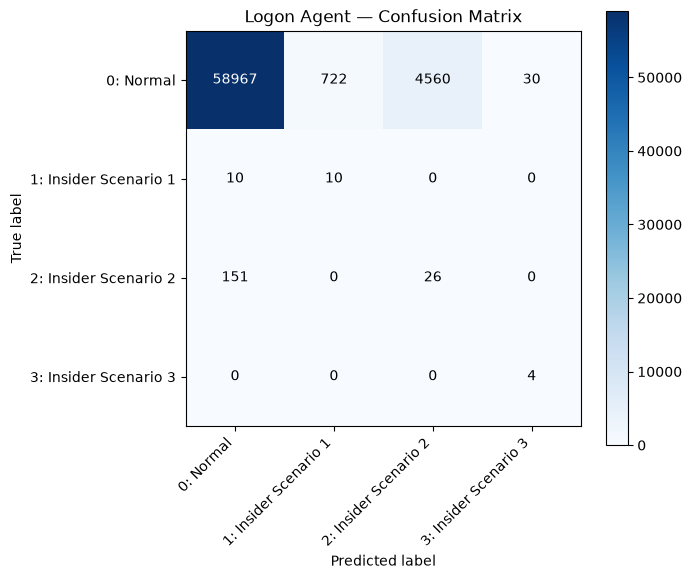


SAMPLE COUNTS
Total test samples: 64480

True samples per class:
  0: Normal: 64279
  1: Insider Scenario 1: 20
  2: Insider Scenario 2: 177
  3: Insider Scenario 3: 4

Predicted samples per class:
  0: Normal: 59128
  1: Insider Scenario 1: 732
  2: Insider Scenario 2: 4586
  3: Insider Scenario 3: 34


In [30]:
# ---------------------------------------------------------------------
# 8. Full evaluation pipeline
# ---------------------------------------------------------------------
 
def evaluate_model(model,
                    test_loader,
                    device,
                    checkpoint_path: str = None,
                    class_names=None):
    """Run the full evaluation pipeline end-to-end:
        1. (Optionally) load best checkpoint into model
        2. Run inference on test_loader
        3. Report overall metrics (macro + weighted)
        4. Print classification report
        5. Compute + plot confusion matrix
        6. Print per-class precision/recall/F1
        7. Print sample counts
 
    If checkpoint_path is provided, the model's weights are (re)loaded
    from that file first. If the model already has the best weights
    loaded (e.g. returned directly from train_model), checkpoint_path
    can be left as None.
    """
    if class_names is None:
        class_names = DEFAULT_CLASS_NAMES
 
    if checkpoint_path is not None:
        model = load_best_model(model, checkpoint_path, device)
    else:
        model = model.to(device)
        model.eval()
 
    y_true, y_pred = get_predictions(model, test_loader, device)
 
    overall_metrics = report_overall_metrics(y_true, y_pred, class_names)
    print()
    print_classification_report(y_true, y_pred, class_names)
    print()
    per_class_metrics = report_per_class_metrics(y_true, y_pred, class_names)
    print()
    cm = compute_confusion_matrix(y_true, y_pred, class_names)
    plot_confusion_matrix(cm, class_names, title="Logon Agent — Confusion Matrix")
    print()
    sample_counts = report_sample_counts(y_true, y_pred, class_names)
 
    return {
        "y_true": y_true,
        "y_pred": y_pred,
        "overall_metrics": overall_metrics,
        "per_class_metrics": per_class_metrics,
        "confusion_matrix": cm,
        "sample_counts": sample_counts,
    }
 
 
# ---------------------------------------------------------------------
# Example usage (assumes model, test_loader, device already exist
# from the previous steps)
# ---------------------------------------------------------------------
 
if __name__ == "__main__":
    # model, test_loader, device are expected to already be in scope
    # from the previous Dataset/DataLoader/Model/Training steps.
    # Not redefined here.
 
    results = evaluate_model(
        model=model,
        test_loader=test_loader,
        device=device,
        checkpoint_path="logon_agent_best_model.pt",
        class_names=DEFAULT_CLASS_NAMES,
    )
 

In [31]:
# Load and prepare dataframe again (official 60/20/20 split)

import pandas as pd

CSV_PATH = DATA_PATH

df = pd.read_csv(CSV_PATH)

# Keep chronological order
df = df.sort_values(['user', 'week', 'day'])

# Official split (loading from data/user_splits/)
from sklearn.model_selection import train_test_split

split = eu.load_official_user_split()

train_users, val_users, test_users = split['train'], split['val'], split['test']

train_df = df[df['user'].isin(train_users)]
val_df   = df[df['user'].isin(val_users)]
test_df  = df[df['user'].isin(test_users)]

print("Training users:  ", len(train_users))
print("Validation users:", len(val_users))
print("Testing users:   ", len(test_users))
print("\nMalicious users in train:")
print(train_df.groupby('user')['insider'].max().value_counts())
print("\nMalicious users in val:")
print(val_df.groupby('user')['insider'].max().value_counts())
print("\nMalicious users in test:")
print(test_df.groupby('user')['insider'].max().value_counts())


Training users:   600
Validation users: 200
Testing users:    200

Malicious users in train:
insider
0    558
1     18
2     18
3      6
Name: count, dtype: int64

Malicious users in val:
insider
0    186
1      6
2      6
3      2
Name: count, dtype: int64

Malicious users in test:
insider
0    186
1      6
2      6
3      2
Name: count, dtype: int64


In [32]:
from collections import Counter
import numpy as np
import torch
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

model.eval()

all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)

        outputs = model(X_batch)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.numpy())
        all_probs.extend(probs.cpu().numpy())

y_pred = np.array(all_preds)
y_test_eval = np.array(all_labels)
y_prob = np.array(all_probs)

# MLflow: record final held-out test metrics under this run.
acc = accuracy_score(y_test_eval, y_pred)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_test_eval, y_pred, average='macro', zero_division=0)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    y_test_eval, y_pred, average='weighted', zero_division=0)

mlflow.log_metrics({
    "test_accuracy": acc,
    "test_macro_precision": macro_p,
    "test_macro_recall": macro_r,
    "test_macro_f1": macro_f1,
    "test_weighted_precision": weighted_p,
    "test_weighted_recall": weighted_r,
    "test_weighted_f1": weighted_f1,
})
mlflow.end_run()

print("Predictions generated:", len(y_pred))
print("Test accuracy: {:.4f}".format(acc))
print("Test macro F1: {:.4f}".format(macro_f1))
print("True insider samples and predictions:")

for cls in [1, 2, 3]:
    idx = (y_test_eval == cls)

    print(f"\nActual class {cls}")
    print("Number of samples:", idx.sum())
    print("Predictions:", Counter(y_pred[idx]))


Predictions generated: 64480
Test accuracy: 0.9151
Test macro F1: 0.3009
True insider samples and predictions:

Actual class 1
Number of samples: 20
Predictions: Counter({np.int64(0): 10, np.int64(1): 10})

Actual class 2
Number of samples: 177
Predictions: Counter({np.int64(0): 151, np.int64(2): 26})

Actual class 3
Number of samples: 4
Predictions: Counter({np.int64(3): 4})
